# Exploratory Data Analysis (EDA) on Retail Sales Dataset

## Objective
To explore retail sales data, identify patterns,
understand customer behaviour, and extract business insights.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("retail_sales_dataset.csv")

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (1000, 9)


In [4]:
print(df.columns)

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [6]:
print(df.isnull().sum())

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [9]:
numeric_columns = df.select_dtypes(include=np.number).columns

print("Numeric Columns:")
print(numeric_columns)

Numeric Columns:
Index(['Transaction ID', 'Age', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')


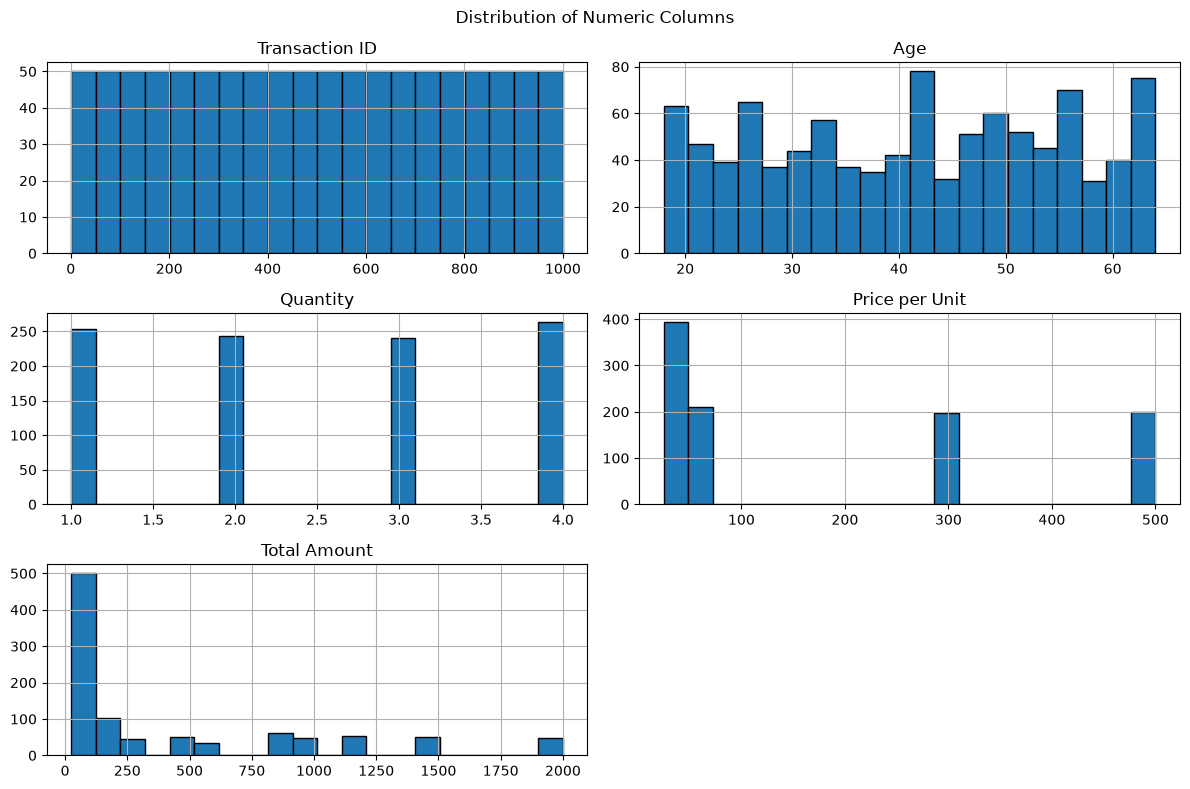

In [10]:
df[numeric_columns].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numeric Columns")
plt.tight_layout()
plt.show()

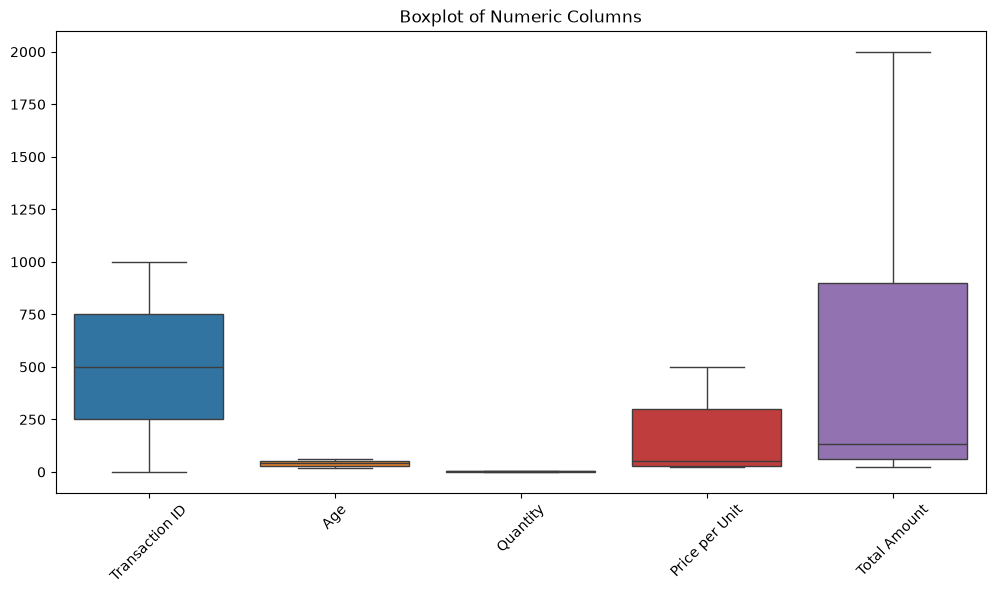

In [11]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[numeric_columns])

plt.title("Boxplot of Numeric Columns")
plt.xticks(rotation=45)
plt.show()

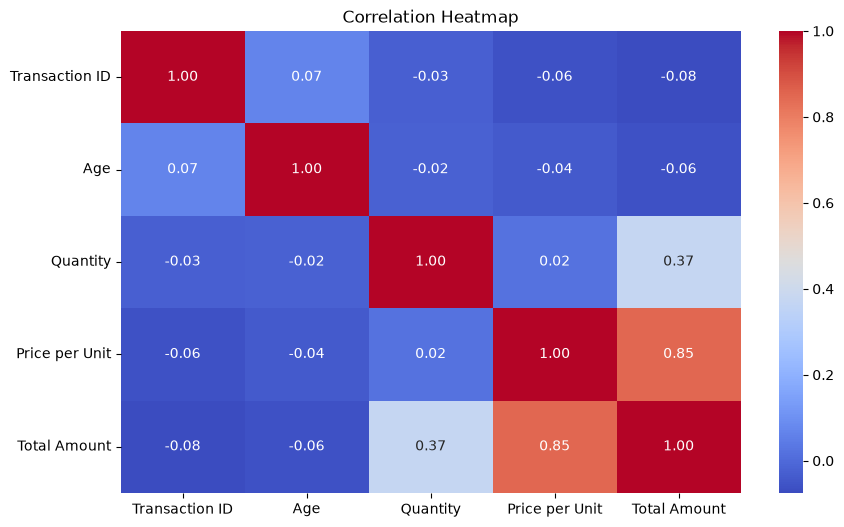

In [12]:
correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

## Business Insights

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


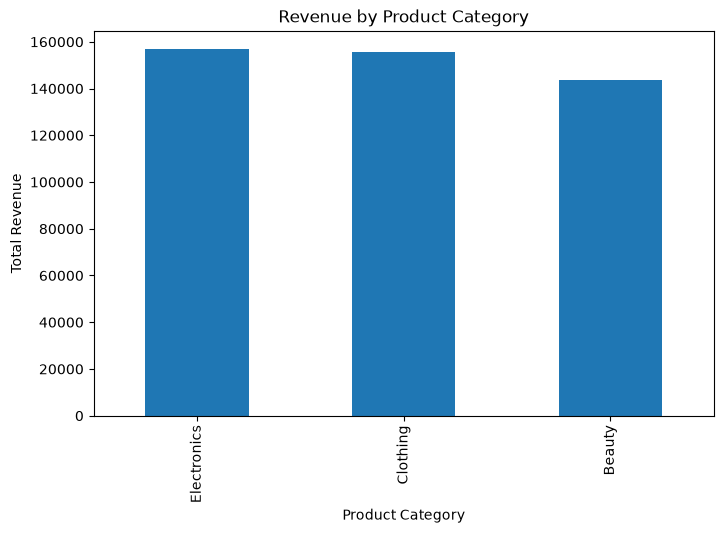

In [13]:
category_sales = df.groupby(
    "Product Category"
)["Total Amount"].sum().sort_values(ascending=False)

print(category_sales)

category_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.show()

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


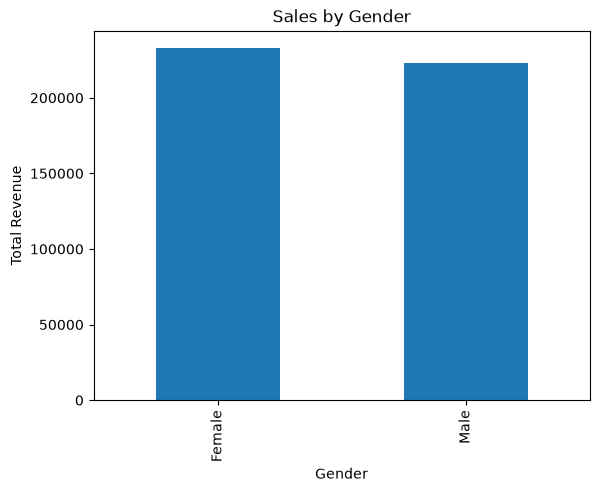

In [14]:
gender_sales = df.groupby("Gender")["Total Amount"].sum()

print(gender_sales)

gender_sales.plot(kind="bar")
plt.title("Sales by Gender")
plt.ylabel("Total Revenue")
plt.show()

Age
18    534.047619
19    708.095238
20    411.666667
21    629.250000
22    507.407407
23    342.500000
24    361.000000
25    495.000000
26    635.454545
27    408.043478
28    412.857143
29    410.625000
30    445.000000
31    464.545455
32    292.105263
33    624.000000
34    599.464286
35    513.181818
36    607.000000
37    728.125000
38    584.210526
39    255.277778
40    392.291667
41    269.047619
42    326.923077
43    579.677419
44    504.000000
45    372.058824
46    523.600000
47    480.961538
48    402.222222
49    268.947368
50    428.043478
51    535.500000
52    320.000000
53    559.411765
54    375.178571
55    465.714286
56    496.842105
57    309.666667
58    528.214286
59    557.058824
60    526.818182
61    373.888889
62    300.740741
63    544.117647
64    294.354839
Name: Total Amount, dtype: float64


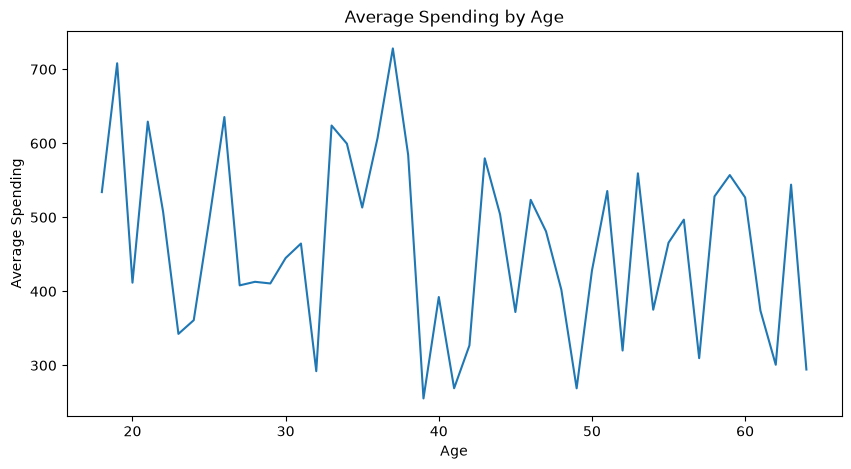

In [15]:
age_spending = df.groupby("Age")["Total Amount"].mean()

print(age_spending)

age_spending.plot(figsize=(10, 5))
plt.title("Average Spending by Age")
plt.xlabel("Age")
plt.ylabel("Average Spending")
plt.show()

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


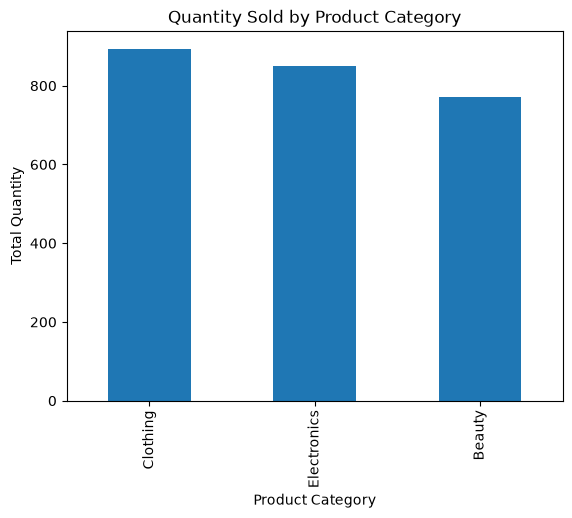

In [16]:
popular_category = df.groupby(
    "Product Category"
)["Quantity"].sum().sort_values(ascending=False)

print(popular_category)

popular_category.plot(kind="bar")
plt.title("Quantity Sold by Product Category")
plt.ylabel("Total Quantity")
plt.show()

Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


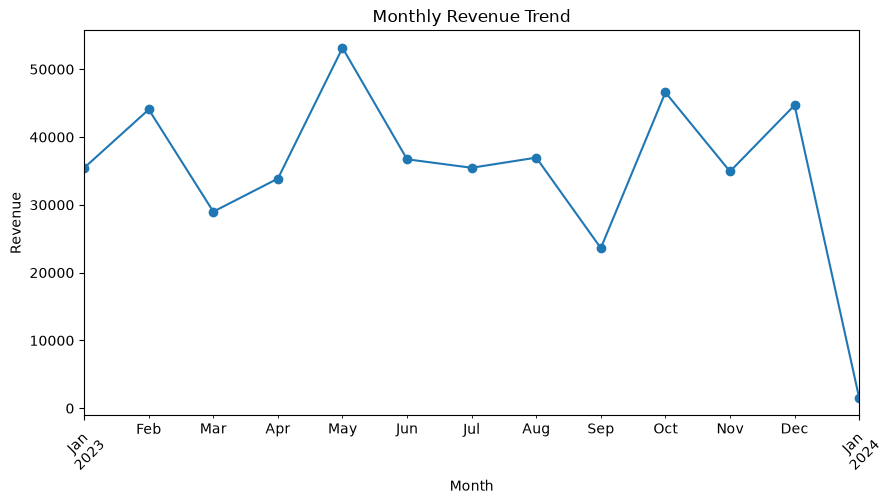

In [17]:
df["Date"] = pd.to_datetime(df["Date"])

df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Total Amount"].sum()

print(monthly_sales)

monthly_sales.astype(float).plot(
    figsize=(10, 5),
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

In [18]:
summary = df.describe().T

summary

,count,mean,min,25%,50%,75%,max,std
Transaction ID,1000.0,500.5,1.0,250.75,500.5,750.25,1000.0,288.819436
Date,1000,2023-07-03 00:25:55.200000,2023-01-01 00:00:00,2023-04-08 00:00:00,2023-06-29 12:00:00,2023-10-04 00:00:00,2024-01-01 00:00:00,NaN
Age,1000.0,41.392,18.0,29.0,42.0,53.0,64.0,13.68143
Quantity,1000.0,2.514,1.0,1.0,3.0,4.0,4.0,1.132734
Price per Unit,1000.0,179.89,25.0,30.0,50.0,300.0,500.0,189.681356
Total Amount,1000.0,456.0,25.0,60.0,135.0,900.0,2000.0,559.997632


## Challenges Faced

- Understanding missing values.
- Identifying outliers.
- Interpreting correlation values.
- Creating meaningful visualisations.

## Tools and Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Final Conclusion

Exploratory Data Analysis helped us understand the
retail sales dataset and identify meaningful business
insights through statistical analysis and visualisation.